# kappa map construction and weighted signal

- real data
- mock data (25 light cones)
- random rotated data (~100 realizations)

S/N ratio estimates:
- signal: real-random
- noise: from random rotation (background)
- shot noise: fluctuation from different cosmology, estimated from mock data

In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils
from scipy.stats import chi2
from astropy.table import Table

In [2]:
# Combine EE signal across fields with per-field covariance from mocks
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field

tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

procedures = [
    'KSI-masking-smooth k',
    'inpainting-KSI-masking-smooth k',
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking',
    'inpainting-smooth g-KSI-masking'
]

full_slice = slice(0, 14)   # same as your notebook
n_mock = 25
mode_names = ['EE', 'EB', 'BB']

array2dict_norandom = lambda arr: {['ls', 'EE', 'EB', 'BB'][i]: arr[:, i] for i in range(arr.shape[1])}
array2dict_k = lambda arr: {['ls', 'EE', 'EB', 'BB', 'EE_rm', 'EE_std', 'EB_rm', 'EB_std', 'BB_rm', 'BB_std'][i]: arr[:, i] for i in range(arr.shape[1])}

# Plot one field for instance

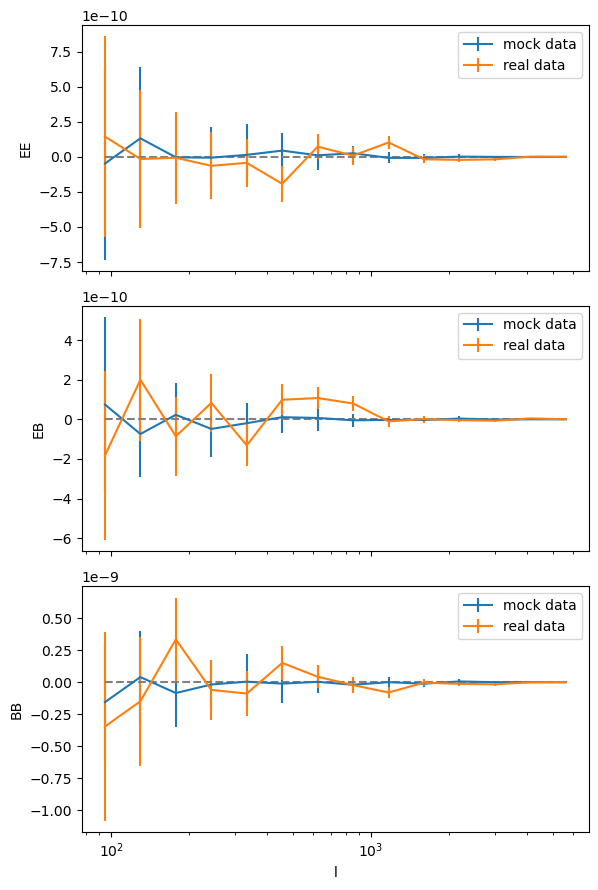

In [5]:
field = 'XMM'
procedure = 'inpainting-KSI-masking-smooth k'
zbin = 1

stat_k = array2dict_k(np.loadtxt(f'results/Cl_results_{field}_{procedure}_z{zbin}.txt'))
# ls, EE, EB, BB, EE_rm, EE_std, EB_rm, EB_std, BB_rm, BB_std
stat_k_mock = [
    array2dict_k(np.loadtxt(f'results/Cl_results_{field}_cone{i}_{procedure}_z{zbin}.txt'))
    for i in range(1, 26)
]

EE_real = stat_k['EE'] - stat_k['EE_rm']
EB_real = stat_k['EB'] - stat_k['EB_rm']
BB_real = stat_k['BB'] - stat_k['BB_rm']

EE_mock = np.array([stat_k_mock[i]['EE'] - stat_k_mock[i]['EE_rm'] for i in range(len(stat_k_mock))])
EB_mock = np.array([stat_k_mock[i]['EB'] - stat_k_mock[i]['EB_rm'] for i in range(len(stat_k_mock))])
BB_mock = np.array([stat_k_mock[i]['BB'] - stat_k_mock[i]['BB_rm'] for i in range(len(stat_k_mock))])

fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)

ax = axes[0]
ax.errorbar(stat_k['ls'], EE_mock.mean(axis=0), EE_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], EE_real, stat_k['EE_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('EE')
ax.legend()

ax = axes[1]
ax.errorbar(stat_k['ls'], EB_mock.mean(axis=0), EB_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], EB_real, stat_k['EB_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('EB')
ax.legend()
# ax.set_xscale('log')

ax = axes[2]
ax.errorbar(stat_k['ls'], BB_mock.mean(axis=0), BB_mock.std(axis=0), label='mock data')
ax.errorbar(stat_k['ls'], BB_real, stat_k['BB_std'], label='real data')
ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
ax.set_ylabel('BB')
ax.set_xlabel('l')
ax.legend()
# ax.set_xscale('log')
ax.set_xscale('log')

plt.tight_layout()

kappa_real = kappa_meas - kappa_rand
kappa_mock = kappa_meas_mock - kappa_rand_mock

kappa_rand has small fluctuation (1,000 10,000) -> squeeze this #random
kappa_mock comes from real fluctuation

kappa_real vs kappa_mock

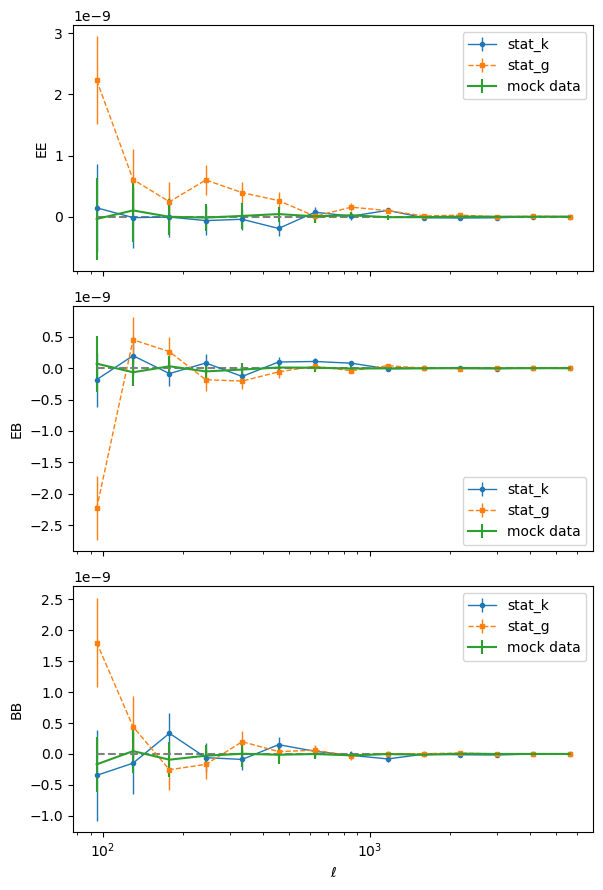

In [6]:
zbin = 2

stat_g = array2dict_k(np.loadtxt(f'results/Cl_results_{field}_smooth_g_z{zbin}_negg2.txt'))
# Compare stat_k and stat_g (real - random) for EE/EB/BB

modes = ['EE', 'EB', 'BB']
fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)

for ax, m in zip(axes, modes):
    y_k = stat_k[m] - stat_k[f'{m}_rm']
    y_g = stat_g[m] - stat_g[f'{m}_rm']
    mock_data = np.array([stat_k_mock[i][m] - stat_k[f'{m}_rm'] for i in range(len(stat_k_mock))])

    ax.errorbar(stat_k['ls'], y_k, yerr=stat_k[f'{m}_std'], fmt='o-', ms=3, lw=1, label='stat_k')
    ax.errorbar(stat_g['ls'], y_g, yerr=stat_g[f'{m}_std'], fmt='s--', ms=3, lw=1, label='stat_g')
    ax.errorbar(stat_k['ls'], mock_data.mean(axis=0), mock_data.std(axis=0), label='mock data')

    ax.hlines(0, stat_k['ls'][0], stat_k['ls'][-1], linestyles='--', colors='grey')
    ax.set_ylabel(m)
    ax.legend()

axes[-1].set_xlabel(r'$\ell$')
axes[-1].set_xscale('log')
plt.tight_layout()
plt.show()


* Check the completeness of calcuclation

In [3]:
procedure = 'smooth g-inpainting-KSI-masking'
for procedure in [
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking',
    'KSI-masking-smooth k',
    'inpainting-KSI-masking-smooth k',
    'KSI-masking',
    'inpainting-KSI-masking'
]:
    for field in name_fields:
        for zbin in [1,2,3,4]:
            if not os.path.isfile(f'results/Cl_results_{field}_{procedure}_z{zbin}.txt'):
                print(f'Missing file: results/Cl_results_{field}_{procedure}_z{zbin}.txt')

In [4]:
for procedure in [
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking',
    'KSI-masking-smooth k',
    'inpainting-KSI-masking-smooth k',
    # 'KSI-masking',
    'inpainting-KSI-masking'
]:
    for field in name_fields:
        for zbin in [1,2,3,4]:
            for i in range(1, 26):
                if not os.path.isfile(f'results/Cl_results_{field}_cone{i}_{procedure}_z{zbin}.txt'):
                    print(f'Missing file: results/Cl_results_{field}_cone{i}_{procedure}_z{zbin}.txt')
                    continue
                if np.loadtxt(f'results/Cl_results_{field}_cone{i}_{procedure}_z{zbin}.txt').shape[1] != 10:
                    print(f'File with wrong shape: results/Cl_results_{field}_cone{i}_{procedure}_z{zbin}.txt')

In [5]:
def weighted_average(mode_name, pipeline, tomo_bin, _slice, weight='inverse_cov'):
    signals = []
    covs = []
    for field in name_fields:
        # Real
        stat_k = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_{pipeline}_z{tomo_bin}.txt"))
        ee_real = stat_k[mode_name] - stat_k[f'{mode_name}_rm']

        # Mocks (for covariance)
        stat_k_mock = [
            array2dict_k(np.loadtxt(f"results/Cl_results_{field}_cone{i}_{pipeline}_z{tomo_bin}.txt"))
            for i in range(1, n_mock + 1)
        ]
        # ee_mock = np.array([m[mode_name] - m[f'{mode_name}_rm'] for m in stat_k_mock])
        ee_mock = np.array([
            m[mode_name] - m[f'{mode_name}_rm'] if f'{mode_name}_rm' in m else m[mode_name] - stat_k[f'{mode_name}_rm'] for m in stat_k_mock
        ])      # to handle cases where mock files don't have _rm columns (use real data's _rm as fallback)

        s = ee_real[_slice]
        C = np.cov(ee_mock[:, _slice], rowvar=False)

        signals.append(s)
        covs.append(C)
        ls = stat_k['ls'][_slice]

    signals = np.array(signals)  # (n_field, nbin)
    nbin = signals.shape[1]

    # weighted with # of galaxies in each field
    if weight == 'galaxy_number':
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()
        s_mean = np.average(signals, axis=0, weights=w)
        C_mean = np.tensordot(w**2, np.array(covs), axes=(0, 0)) / (wsum**2)
        chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return ls, s_mean, C_mean, chi2_val
    elif weight == 'inverse_cov':
    # 3) Inverse-cov weighted (recommended): s_icov, C_icov
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)
        for s, C in zip(signals, covs):
            # use solve for better stability than explicit inverse
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b
        # S/N for combined signal (pick which combo you want)
        chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)

        return ls, s_icov, C_icov, chi2_val
    else:
        raise ValueError("Invalid weight option")
    

def weighted_average_shear(mode_name, tomo_bin, _slice, weight='inverse_cov', use_legacy=False):
    signals, covs = [], []

    for field in name_fields:
        # Real shear signal
        if use_legacy:
            # stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_smooth.txt"))      # smoothed here.
            stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_shear_{field}_z{tomo_bin}_negg2_masked_smooth.txt"))      # smoothed here.
        else:
            stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_cmp.txt"))         # no smooth

        s_real = stat_g[mode_name] - stat_g[f"{mode_name}_rm"]

        s = s_real[_slice]
        C = np.diag(stat_g[f"{mode_name}_std"][_slice] ** 2)        # currently no mock for shear (maybe add it later)

        signals.append(s)
        covs.append(C)
        ls = stat_g["ls"][_slice]

    signals = np.asarray(signals)
    covs = np.asarray(covs)
    nbin = signals.shape[1]

    if weight == "galaxy_number":
        # Per-tomobin galaxy counts
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()

        s_mean = np.average(signals, axis=0, weights=w)
        C_mean = np.tensordot(w**2, covs, axes=(0, 0)) / (wsum**2)
        chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return ls, s_mean, C_mean, chi2_val

    elif weight == "inverse_cov":
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)

        for s, C in zip(signals, covs):
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b
        chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)
        return ls, s_icov, C_icov, chi2_val
    else:
        raise ValueError("Invalid weight option")

In [ ]:
def weighted_average_signoise(mode_name, pipeline, tomo_bin, _slice, weight='inverse_cov'):
    signals = []
    covs = []
    for field in name_fields:
        # Real
        stat_k = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_{pipeline}_z{tomo_bin}.txt"))
        ee_real = stat_k[mode_name]
        
        # Mocks (for covariance)
        stat_k_mock = [
            array2dict_k(np.loadtxt(f"results/Cl_results_{field}_cone{i}_{pipeline}_z{tomo_bin}.txt"))
            for i in range(1, n_mock + 1)
        ]
        # ee_mock = np.array([m[mode_name] - m[f'{mode_name}_rm'] for m in stat_k_mock])
        ee_mock = np.array([
            m[mode_name] for m in stat_k_mock
        ])

        s = ee_real[_slice]
        C = np.cov(ee_mock[:, _slice], rowvar=False)

        signals.append(s)
        covs.append(C)
        ls = stat_k['ls'][_slice]

    signals = np.array(signals)  # (n_field, nbin)
    nbin = signals.shape[1]

    # weighted with # of galaxies in each field
    if weight == 'galaxy_number':
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()
        s_mean = np.average(signals, axis=0, weights=w)
        C_mean = np.tensordot(w**2, np.array(covs), axes=(0, 0)) / (wsum**2)
        chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return ls, s_mean, C_mean, chi2_val
    elif weight == 'inverse_cov':
    # 3) Inverse-cov weighted (recommended): s_icov, C_icov
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)
        for s, C in zip(signals, covs):
            # use solve for better stability than explicit inverse
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b
        # S/N for combined signal (pick which combo you want)
        chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)

        return ls, s_icov, C_icov, chi2_val
    else:
        raise ValueError("Invalid weight option")

def weighted_average_shear_signoise(mode_name, tomo_bin, _slice, weight='inverse_cov', use_legacy=False, name_fields=name_fields):
    signals, covs = [], []
    for field in name_fields:
        # Real shear signal
        if use_legacy:
            # stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_smooth.txt"))
            stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_shear_{field}_z{tomo_bin}_negg2_masked_smooth.txt"))      # smoothed here.
        else:
            stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_shear_{field}_z{tomo_bin}_negg2_unsmooth.txt"))

        s_real = stat_g[mode_name]

        s = s_real[_slice]
        C = np.diag(stat_g[f"{mode_name}_std"][_slice] ** 2)        # currently no mock for shear (maybe add it later)

        signals.append(s)
        covs.append(C)
        ls = stat_g["ls"][_slice]

    signals = np.asarray(signals)
    covs = np.asarray(covs)
    nbin = signals.shape[1]

    if weight == "galaxy_number":
        # Per-tomobin galaxy counts
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()

        s_mean = np.average(signals, axis=0, weights=w)
        C_mean = np.tensordot(w**2, covs, axes=(0, 0)) / (wsum**2)
        chi2_val = s_mean @ np.linalg.solve(C_mean, s_mean)
        return ls, s_mean, C_mean, chi2_val

    elif weight == "inverse_cov":
        P = np.zeros((nbin, nbin))
        b = np.zeros(nbin)

        for s, C in zip(signals, covs):
            P += np.linalg.solve(C, np.eye(nbin))
            b += np.linalg.solve(C, s)

        C_icov = np.linalg.inv(P)
        s_icov = C_icov @ b
        chi2_val = s_icov @ np.linalg.solve(C_icov, s_icov)
        return ls, s_icov, C_icov, chi2_val
    else:
        raise ValueError("Invalid weight option")

In [13]:
for field in name_fields:
    for tomo_bin in [1, 2, 3, 4]:
        if os.path.isfile(f'results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_cmp.txt'):
            os.rename(f'results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_cmp.txt', f'results/Cl_results_shear_{field}_z{tomo_bin}_negg2_unsmooth.txt')
        else:
            print(f'Missing file for renaming: results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_cmp.txt')

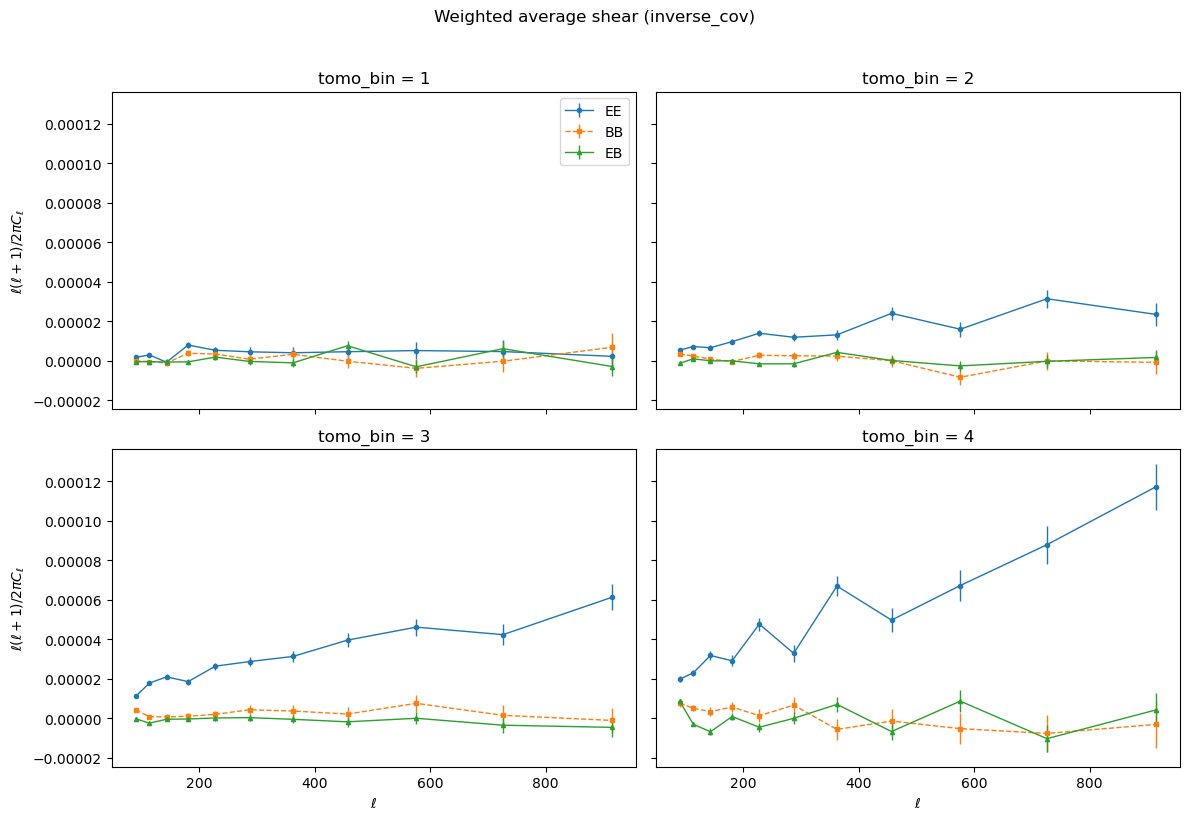

In [7]:
# 4 tomographic bins, weighted-average shear, plotted as l(l+1)Cl / 2pi
tomobins = [1, 2, 3, 4]
modes = ["EE", "BB", "EB"]
selected_slice = slice(0, 11)
weight = 'inverse_cov'  # 'inverse_cov' or 'galaxy_number'

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, tb in zip(axes, tomobins):
    for mode_name, fmt in zip(modes, ["o-", "s--", "^-"]):
        ls, s_g, C_gg, _ = weighted_average_shear(
            mode_name, tb, selected_slice, weight=weight
        )
        ell_factor = ls * (ls + 1) / (2 * np.pi)
        y = ell_factor * s_g
        yerr = ell_factor * np.sqrt(np.diag(C_gg))
        ax.errorbar(ls, y, yerr=yerr, fmt=fmt, ms=3, lw=1, label=mode_name)

    ax.axhline(0, ls.min(), ls.max(), ls="--", color="gray")
    ax.set_title(f"tomo_bin = {tb}")
# axes[0].set_xscale("log")
axes[0].legend()
for ax in axes[2:]:
    ax.set_xlabel(r"$\ell$")
for ax in [axes[0], axes[2]]:
    ax.set_ylabel(r"$\ell(\ell+1) / 2\pi C_\ell$")

plt.suptitle(f"Weighted average shear ({weight})", y=1.02)
plt.tight_layout()
plt.show()

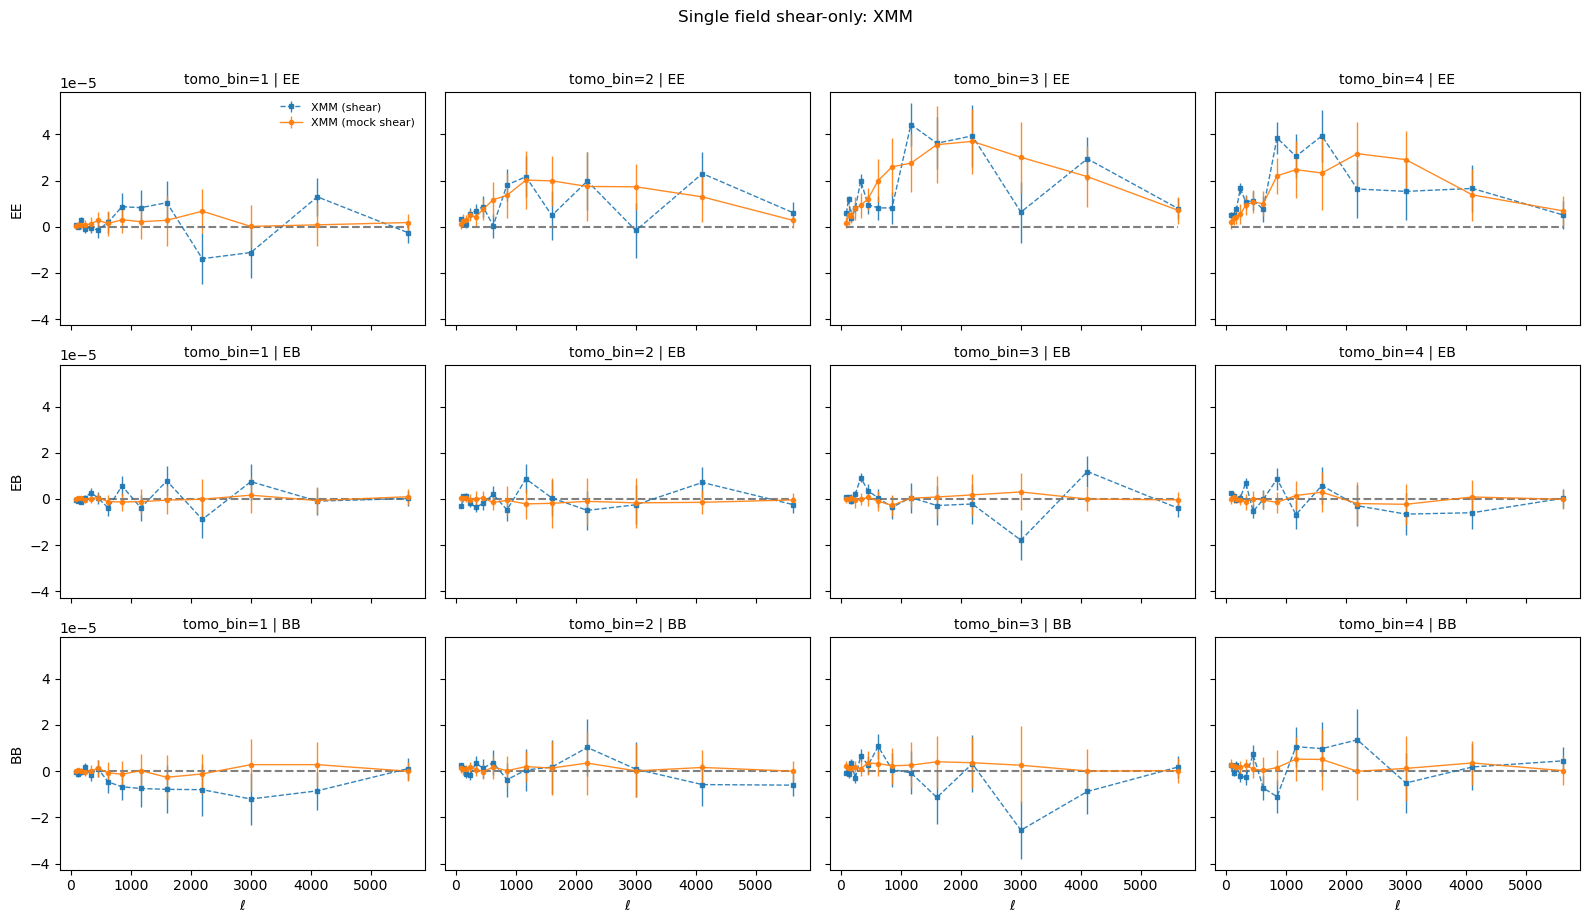

In [ ]:
# Single-field shear-only comparison across 4 tomographic bins

l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner
ells_uncoupled = binner.get_effective_ells()


tomo_bin_list = [1, 2, 3, 4]
selected_slice = slice(0, 14)

modes = ["EE", "EB", "BB"]

field_to_plot = 'XMM'

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for j, tb in enumerate(tomo_bin_list):
    g_mock = [
        array2dict_k(np.loadtxt(f'results/Cl_results_{field_to_plot}_cone{i}_smooth_g_z{tb}_negg2.txt'))
        for i in range(1, n_mock + 1)
    ]

    for i, mode_name in enumerate(modes):
        ax = axes[i, j]

        stat_g_f = array2dict_k(np.loadtxt(f"results/Cl_results_{field_to_plot}_smooth_g_z{tb}_negg2.txt"))

        # ls = stat_g_f["ls"][selected_slice]
        ls = ells_uncoupled[selected_slice]  # use binner's effective ells for x-axis
        ell_factor = ls * (ls + 1) / (2 * np.pi)
        y_g = (stat_g_f[mode_name] - stat_g_f[f"{mode_name}_rm"])[selected_slice] * ell_factor
        yerr_g = stat_g_f[f"{mode_name}_std"][selected_slice] * ell_factor

        ax.errorbar(ls, y_g, yerr_g, fmt="s--", ms=3, lw=1, alpha=0.9, label=f"{field_to_plot} (shear)")

        ee_mock = np.array([m[mode_name] - m[f'{mode_name}_rm'] for m in g_mock])
        ee_mock_mean = ee_mock.mean(axis=0)[selected_slice] * ell_factor
        ee_mock_std = ee_mock.std(axis=0)[selected_slice] * ell_factor
        ax.errorbar(ls, ee_mock_mean, yerr=ee_mock_std, fmt='o-', ms=3, lw=1, alpha=0.9, label=f"{field_to_plot} (mock shear)")

        ax.hlines(0, ls.min(), ls.max(), linestyles="--", colors="grey")
        ax.set_title(f"tomo_bin={tb} | {mode_name}", fontsize=10)

        if j == 0:
            ax.set_ylabel(mode_name)
        if i == 2:
            ax.set_xlabel(r"$\ell$")

axes[0, 0].legend(fontsize=8, frameon=False)
# axes[0, 0].set_xscale("log")
plt.suptitle(f"Single field shear-only: {field_to_plot}", y=1.02)
plt.tight_layout()
plt.show()

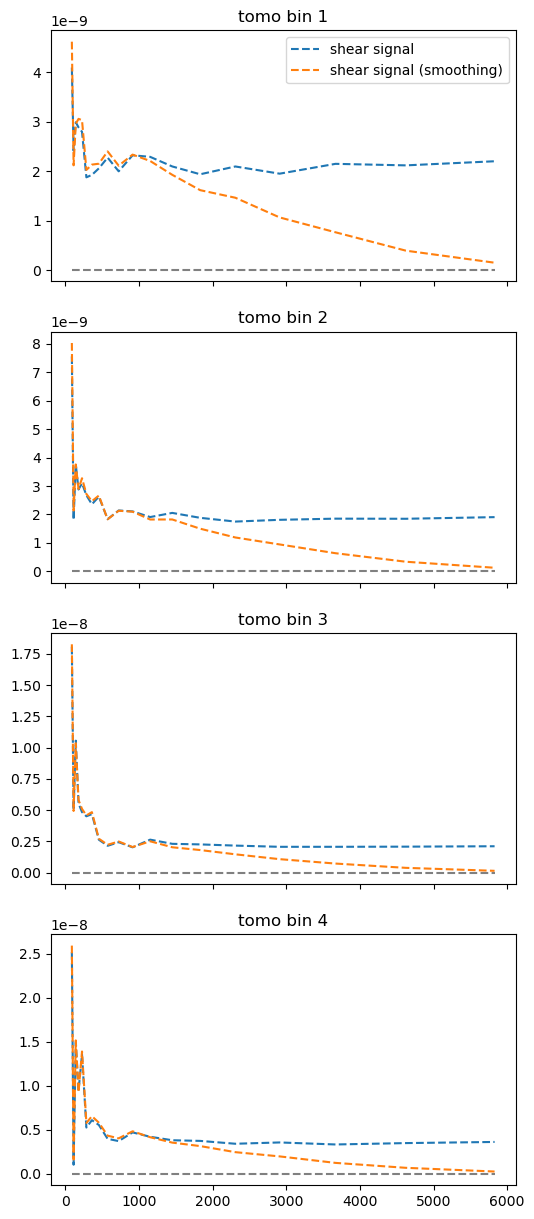

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(6, 15), sharex=True)

selected_slice = slice(None, None)
weight = 'galaxy_number'  # 'inverse_cov' or 'galaxy_number'

mode_name = 'EE'

for tomo in [1, 2, 3, 4]:
    ax = axes[tomo-1]
    # procedure = 'inpainting-KSI-masking'
    # ls, s_icov, C_icov, SN_icov = weighted_average_signoise(mode_name, procedure, tomo, selected_slice, weight=weight)
    # ax.errorbar(ls, s_icov, np.sqrt([C_icov[i,i] for i in range(len(ls))]), label=procedure)

    # procedure = 'KSI-masking-smooth k'
    # ls, s_icov, C_icov, SN_icov = weighted_average_signoise(mode_name, procedure, tomo, selected_slice, weight=weight)
    # ax.errorbar(ls, s_icov, np.sqrt([C_icov[i,i] for i in range(len(ls))]), label=procedure)

    ls, s_g, C_gg, SN_g = weighted_average_shear_signoise(mode_name, tomo, selected_slice, weight=weight, name_fields=['XMM'])
    ax.plot(ls, s_g, marker='', linestyle='--', label='shear signal')

    ls, s_g, C_gg, SN_g = weighted_average_shear_signoise(mode_name, tomo, selected_slice, weight=weight, use_legacy=True, name_fields=['XMM'])
    ax.plot(ls, s_g, marker='', linestyle='--', label='shear signal (smoothing)')
    ax.hlines(0, ls.min(), ls.max(), linestyles='--', colors='grey')
    ax.set_title(f'tomo bin {tomo}')
# axes[0].set_xlim(0, 1000)
axes[0].legend()

Text(0.5, 1.0, 'WIDE12H tomo_bin 3 shear EE')

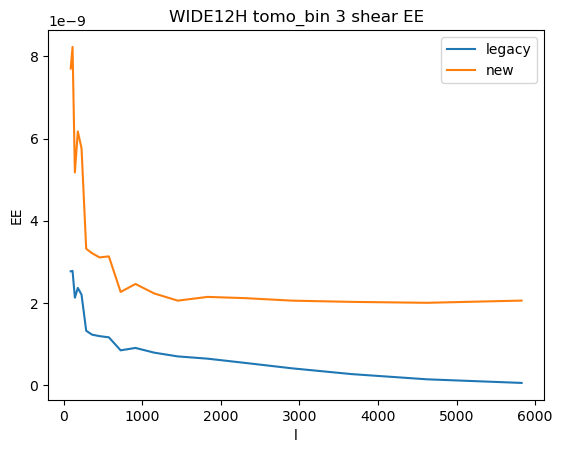

In [ ]:
field = 'WIDE12H'
tomo_bin = 3

stat_g_legacy = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_smooth.txt"))
stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2_cmp.txt"))

plt.plot(stat_g_legacy['ls'], stat_g_legacy['EE'], label='legacy')
plt.plot(stat_g['ls'], stat_g['EE'], label='new')
plt.legend()
plt.xlabel('l')
plt.ylabel('EE')
plt.title(f'{field} tomo_bin {tomo_bin} shear EE')

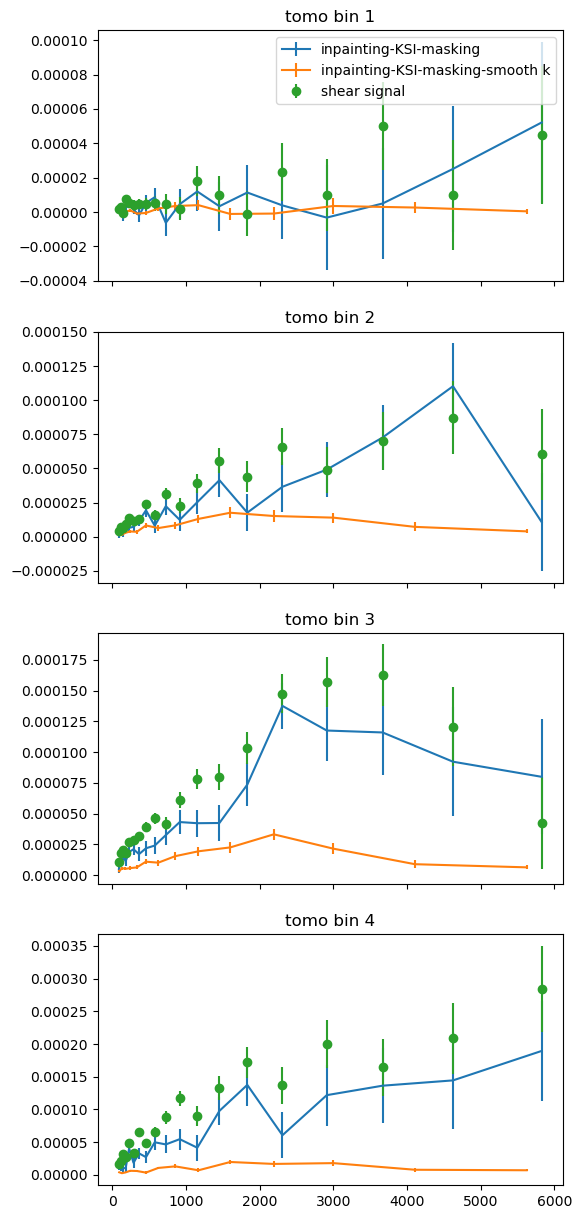

In [39]:
fig, axes = plt.subplots(4, 1, figsize=(6, 15), sharex=True)

procedure = 'inpainting-KSI-masking'
selected_slice = slice(None, None)

mode_name = 'EE'
for tomo in [1, 2, 3, 4]:
    ax = axes[tomo-1]
    procedure = 'inpainting-KSI-masking'
    ls, s_icov, C_icov, SN_icov = weighted_average(mode_name, procedure, tomo, selected_slice, weight=weight)

    factor = ls * (ls + 1) / (2 * np.pi)
    ax.errorbar(ls, s_icov * factor, np.sqrt([C_icov[i,i] for i in range(len(ls))]) * factor, label=procedure)

    procedure = 'inpainting-KSI-masking-smooth k'
    ls, s_icov, C_icov, SN_icov = weighted_average(mode_name, procedure, tomo, selected_slice, weight=weight)
    factor = ls * (ls + 1) / (2 * np.pi)
    ax.errorbar(ls, s_icov * factor, np.sqrt([C_icov[i,i] for i in range(len(ls))]) * factor, label=procedure)

    ls, s_g, C_gg, SN_g = weighted_average_shear(mode_name, tomo, selected_slice, weight=weight)
    factor = ls * (ls + 1) / (2 * np.pi)
    ax.errorbar(ls, s_g * factor, np.sqrt([C_gg[i,i] for i in range(len(ls))]) * factor, marker='o', linestyle='', label='shear signal')
    # ax.hlines(0, ls.min(), ls.max(), linestyles='--', colors='grey')
    ax.set_title(f'tomo bin {tomo}')
# axes[0].set_xlim(0, 1000)
axes[0].legend()

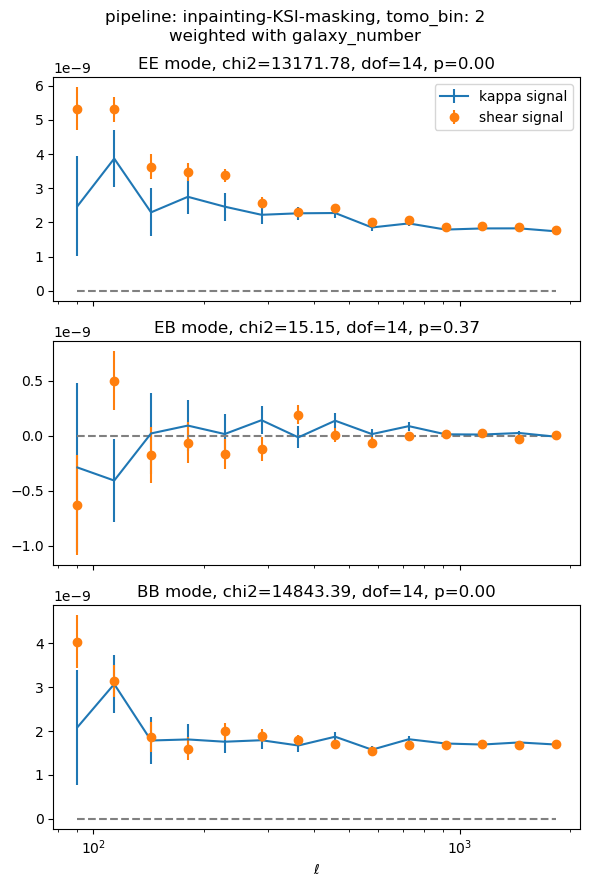

In [20]:
# plot 3 modes for example

name_fields = [
    'XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'HECTOMAP', 'WIDE12H'
]

selected_slice = slice(0, 14)
weight = 'galaxy_number'  # 'inverse_cov' or 'galaxy_number'
tomo_bin = 2

procedure = 'inpainting-KSI-masking'
fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
for mode_name, ax in zip(['EE', 'EB', 'BB'], axes):
    ls, s_icov, C_icov, SN_icov = weighted_average_signoise(mode_name, procedure, tomo_bin, selected_slice, weight=weight)
    _, s_g, C_gg, SN_g = weighted_average_shear_signoise(mode_name, tomo_bin, selected_slice, weight=weight)

    ax.errorbar(ls, s_icov, np.sqrt([C_icov[i,i] for i in range(len(ls))]), label='kappa signal')
    ax.errorbar(ls, s_g, np.sqrt([C_gg[i,i] for i in range(len(ls))]), marker='o', linestyle='', label='shear signal')
    ax.hlines(0, ls.min(), ls.max(), linestyles='--', colors='grey')
    ax.set_title(f'{mode_name} mode, chi2={SN_icov:.2f}, dof={len(ls)}, p={chi2.sf(SN_icov, len(ls)):.2f}')
    # ax.set_yscale('log')

axes[0].legend()
axes[-1].set_xscale('log')

axes[-1].set_xlabel(r'$\ell$')
plt.suptitle(f'pipeline: {procedure}, tomo_bin: {tomo_bin}\nweighted with {weight}')
plt.tight_layout()

suffix_str = ''
if weight == 'inverse_cov':
    suffix_str = 'w1'
elif weight == 'galaxy_number':
    suffix_str = 'w2'
# plt.savefig(f'figs/weighted_average/all_weighted_result_{procedure}_z{tomo_bin}_{suffix_str}.pdf')
plt.show()

In [ ]:
_slice = slice(0, 14)
for tomo_bin in [1, 2, 3, 4]:
    f = open(f'/home/hedi/HSCNG/shear_z{tomo_bin}', 'w')
    for mode_name in ['EE', 'EB', 'BB']:
        signals = []
        covs = []
        signals_noise = []
        for field in name_fields:
            # Real shear signal
            stat_g = array2dict_k(np.loadtxt(f"results/Cl_results_{field}_smooth_g_z{tomo_bin}_negg2.txt"))

            s_real = stat_g[mode_name]
            s_noise = stat_g[f"{mode_name}_rm"]

            s = s_real[_slice]
            s_n = s_noise[_slice]

            C = np.diag(stat_g[f"{mode_name}_std"][_slice] ** 2)        # currently no mock for shear (maybe add it later)

            signals.append(s)
            covs.append(C)
            signals_noise.append(s_n)
            ls = stat_g["ls"][_slice]

        signals = np.asarray(signals)
        covs = np.asarray(covs)
        signals_noise = np.asarray(signals_noise)
        nbin = signals.shape[1]
        # Per-tomobin galaxy counts
        number_galaxies = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo_bin - 1] for field in name_fields
        ]
        w = np.asarray(number_galaxies, dtype=float)
        wsum = w.sum()

        s_mean = np.average(signals, axis=0, weights=w)
        s_n_mean = np.average(signals_noise, axis=0, weights=w)
        C_mean = np.tensordot(w**2, covs, axes=(0, 0)) / (wsum**2)
        s_subs = s_mean - s_n_mean
        chi2_val = s_subs @ np.linalg.solve(C_mean, s_subs)

        table = Table({
            'ls': ls,
            'Nl': s_n_mean,
            'Cl': s_subs,
            'Cl+Nl': s_mean,
            'error': np.sqrt(np.diag(C_mean))
        })
        f.write(f"# {mode_name} mode\n")
        table.write(f, format='csv')
        f.write("\n")

    f.close()

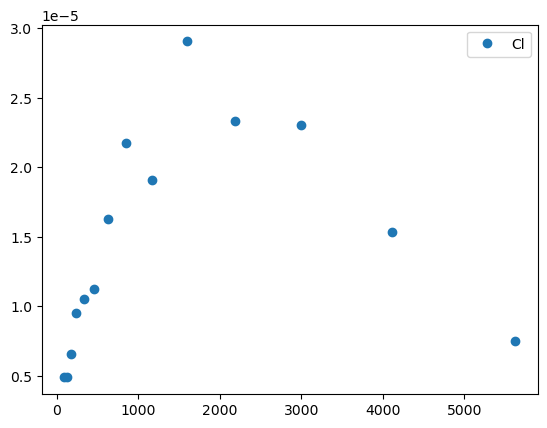

In [30]:
table = Table.read('/home/hedi/HSCNG/EE_z4', format='ascii')
# plt.plot(table['ls'], table['Cl+Nl'] * table['ls'] * (table['ls'] + 1) / (2 * np.pi), 'o', label='Cl+Nl')
# plt.plot(table['ls'], table['Nl'] * table['ls'] * (table['ls'] + 1) / (2 * np.pi), 'o', label='Nl')
plt.plot(table['ls'], table['Cl'] * table['ls'] * (table['ls'] + 1) / (2 * np.pi), 'o', label='Cl')
plt.legend()

<ErrorbarContainer object of 3 artists>

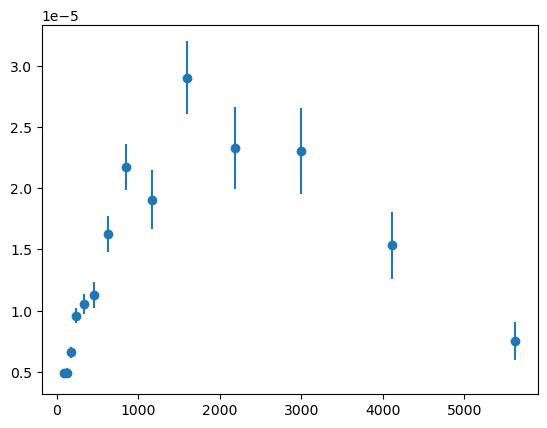

In [17]:
plt.errorbar(table['ls'], table['Cl'] * table['ls'] * (table['ls'] + 1) / (2 * np.pi), yerr=table['error'] * table['ls'] * (table['ls'] + 1) / (2 * np.pi), fmt='o')

# compare different pipelines and weighting strategy

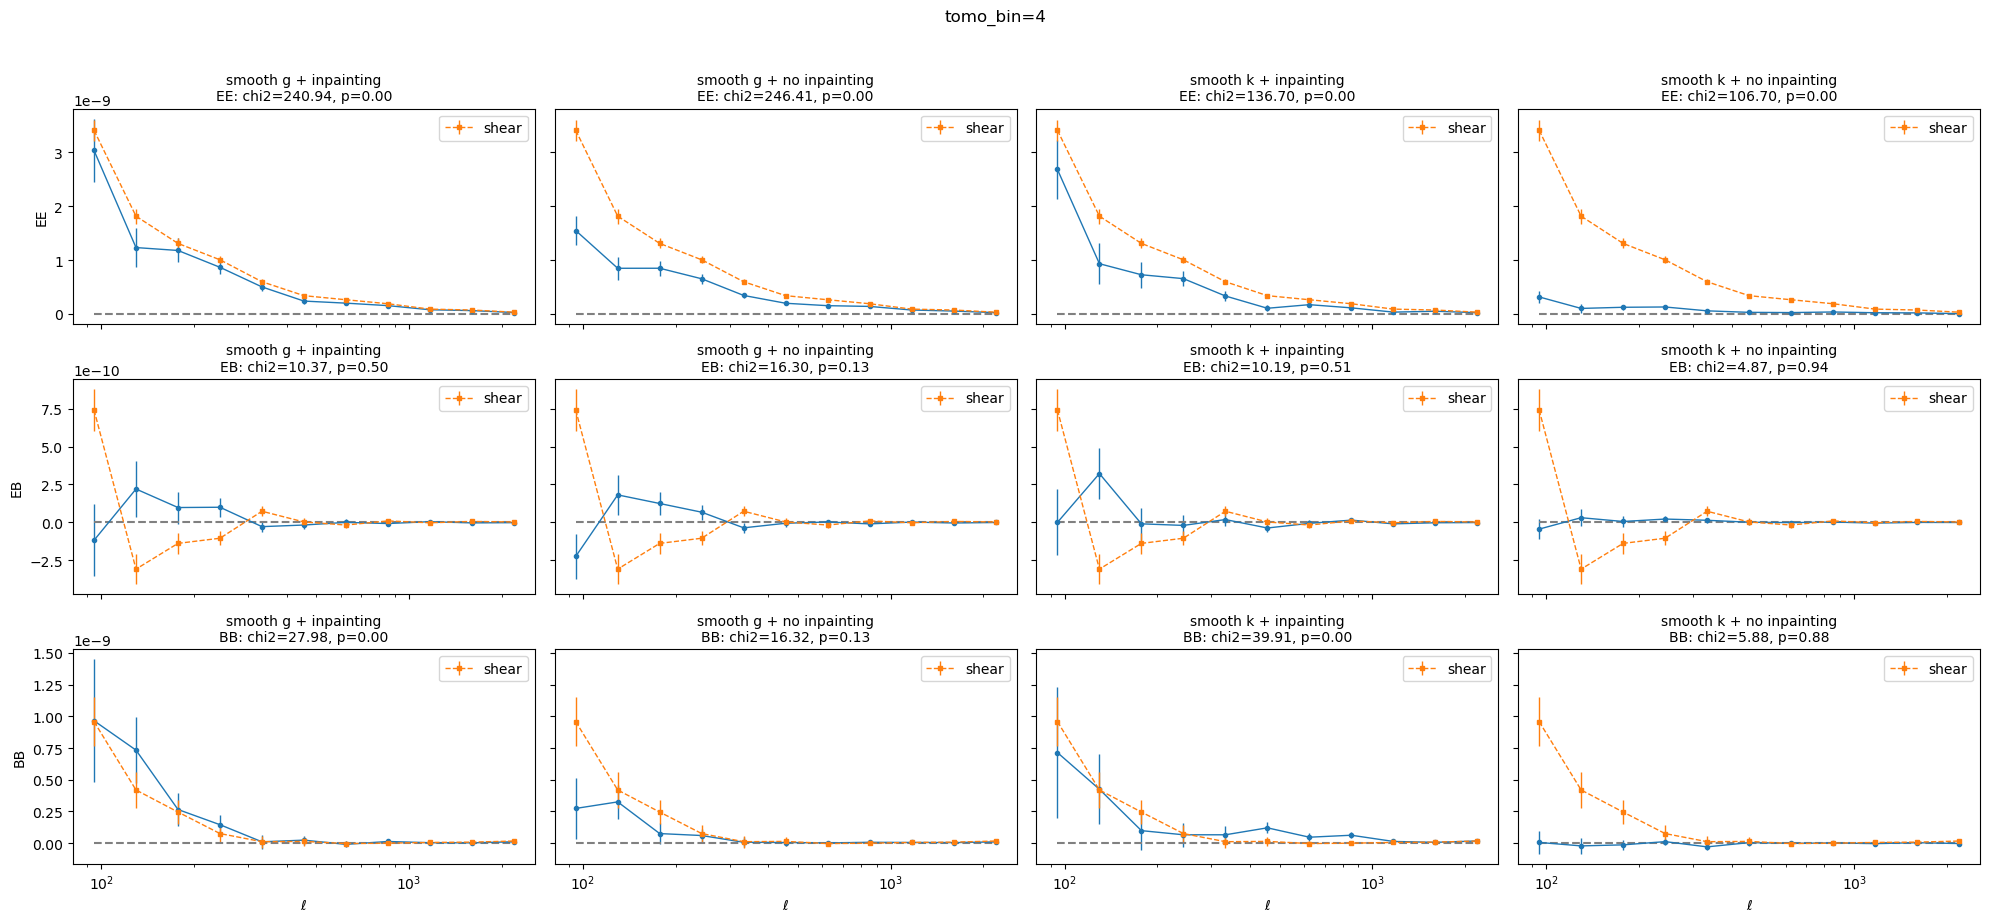

In [47]:
tomo_bin = 4

configs = [
    ("smooth g-inpainting-KSI-masking", "galaxy_number", "smooth g + inpainting"),
    ("smooth g-KSI-masking", "galaxy_number", "smooth g + no inpainting"),
    ("inpainting-KSI-masking-smooth k", "galaxy_number", "smooth k + inpainting"),
    ("KSI-masking-smooth k", "galaxy_number", "smooth k + no inpainting")
]

fig, axes = plt.subplots(3, 4, figsize=(20, 9), sharex=True, sharey='row')

for j, (pipeline, w, col_title) in enumerate(configs):
    for i, mode_name in enumerate(["EE", "EB", "BB"]):
        ax = axes[i, j]
        ls, s_mean, C_mean, chi2_val = weighted_average(
            mode_name, pipeline, tomo_bin, selected_slice, weight=w
        )
        _, s_g, C_gg, SN_g = weighted_average_shear(mode_name, tomo_bin, selected_slice, weight=w)
        yerr = np.sqrt(np.diag(C_mean))

        ax.errorbar(ls, s_mean, yerr, fmt="o-", ms=3, lw=1)
        ax.errorbar(ls, s_g, np.sqrt(np.diag(C_gg)), fmt="s--", ms=3, lw=1, label="shear")
        ax.hlines(0, ls.min(), ls.max(), linestyles="--", colors="grey")

        pval = chi2.sf(chi2_val, len(ls))
        ax.set_title(f"{col_title}\n{mode_name}: chi2={chi2_val:.2f}, p={pval:.2f}", fontsize=10)
        if j == 0:
            ax.set_ylabel(mode_name)
        if i == 2:
            ax.set_xlabel(r"$\ell$")
        ax.legend()
        # ax.set_xlim(100, 2000)

axes[0, 0].set_xscale("log")

plt.suptitle(f"tomo_bin={tomo_bin}", y=1.02)
plt.tight_layout()

plt.savefig(f"figs/weighted_average/comparison_z{tomo_bin}.pdf")
plt.show()

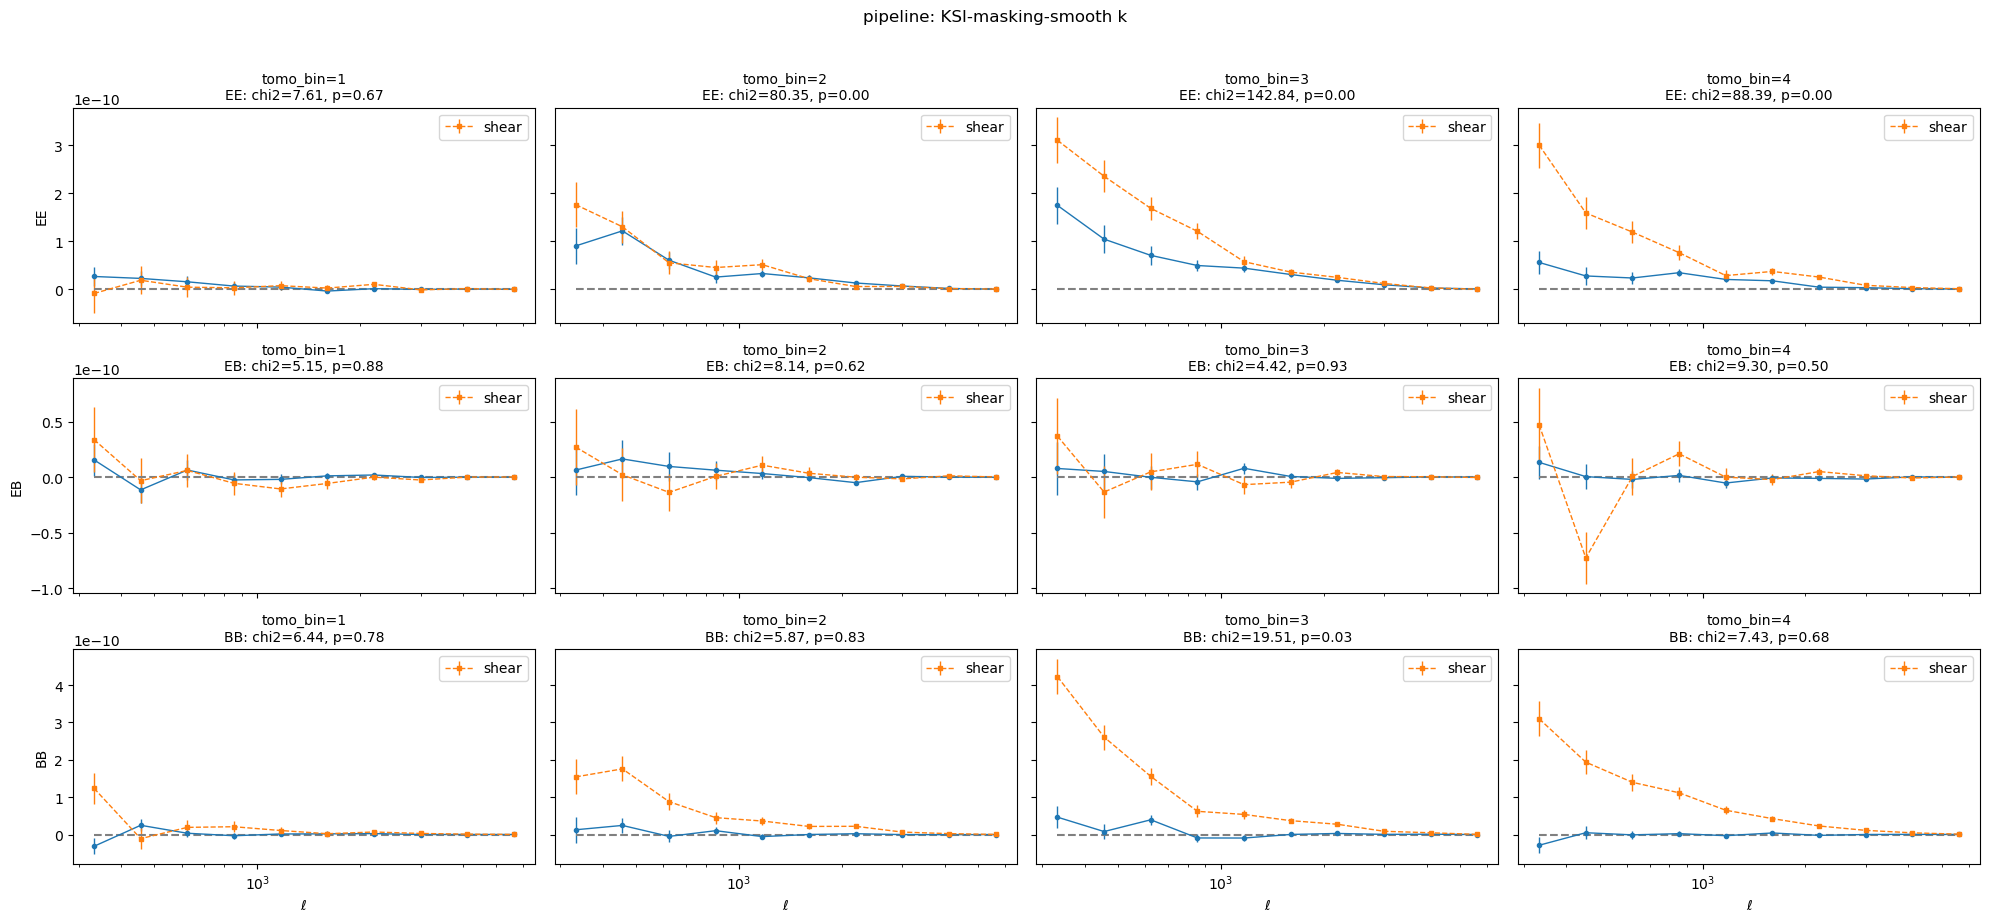

In [38]:
tomo_bin_list = [1, 2, 3, 4]
pipeline = "KSI-masking-smooth k"
w = "galaxy_number"
selected_slice = slice(4, 14)

fig, axes = plt.subplots(3, 4, figsize=(20, 9), sharex=True, sharey='row')

for j, tomo_bin in enumerate(tomo_bin_list):
    for i, mode_name in enumerate(["EE", "EB", "BB"]):
        ax = axes[i, j]
        ls, s_mean, C_mean, chi2_val = weighted_average(
            mode_name, pipeline, tomo_bin, selected_slice, weight=w
        )
        yerr = np.sqrt(np.diag(C_mean))

        ax.errorbar(ls, s_mean, yerr, fmt="o-", ms=3, lw=1)
        _, s_g, C_gg, SN_g = weighted_average_shear(mode_name, tomo_bin, selected_slice, weight=w)

        ax.errorbar(ls, s_g, np.sqrt(np.diag(C_gg)), fmt="s--", ms=3, lw=1, label="shear")
        ax.hlines(0, ls.min(), ls.max(), linestyles="--", colors="grey")

        pval = chi2.sf(chi2_val, len(ls))
        ax.set_title(f"tomo_bin={tomo_bin}\n{mode_name}: chi2={chi2_val:.2f}, p={pval:.2f}", fontsize=10)
        if j == 0:
            ax.set_ylabel(mode_name)
        if i == 2:
            ax.set_xlabel(r"$\ell$")
        ax.legend()

axes[0, 0].set_xscale("log")

plt.suptitle(f"pipeline: {pipeline}", y=1.02)
plt.tight_layout()

plt.savefig(f"figs/weighted_average/comparison_{pipeline}.pdf")
plt.show()